# MINT final test (E5, OPV2V): results notebook

Reads **only** the two analysis summaries (`e5_v3.json` from `v3_analyze`, `e5_test.json` from the frozen v2 `e5_analyze`) and shows every pre-registered statistic, figure and check. Nothing is recomputed; the numbers are those in the files. The status banner says whether these are final-test results or development numbers. An incomplete final test stops the notebook (pre-registered rule: no AP or criteria on partial results).

To point it at the final test, change the paths in the next cell to `runs/20261024-E5v3/e5_v3.json` and `runs/20261024-E5v3/e5_test.json`.

In [1]:
# Inputs (relative to the repository root)
V3 = 'runs/20261024-E5v3/e5_v3.json'
V2 = 'runs/20261024-E5v3/e5_test.json'
PREREG = 'runs/20261024-E5/preregistration_v3_2.json'


In [2]:
import os, sys, time, platform
from IPython.display import Markdown, display
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'src'))
import io
import matplotlib.pyplot as plt
from IPython.display import Image
from mint.report import style, tables as T
from mint.report.data import Inputs, DEFS, DEF_NAME
from mint.report.figures import FIGURES
T0 = time.time()
inp = Inputs(os.path.join(ROOT, V3), os.path.join(ROOT, V2) if V2 else None,
             os.path.join(ROOT, PREREG) if PREREG else None, root=ROOT)
if inp.status == 'INCOMPLETE':
    raise SystemExit('STOP: the final-test analysis is flagged incomplete; no AP or criteria on partial results.')
display(Markdown(f'> **Status: {inp.status_text}**  \n> {inp.label}'))

> **Status: FINAL TEST (one-time)**  
> FINAL TEST (one-time), v3 analysis

## Provenance

In [3]:
p = inp.provenance()
rows = [[k, f"`{v['path']}`", f"`{v['sha256'][:16]}...`"] for k, v in p['inputs'].items()]
rows += [['git HEAD', f"`{p['git_head']}`", ''], ['frozen code commit', f"`{p['frozen_code_commit']}`", ''],
         ['scenarios / frames', f'{inp.n_scenarios()} / {inp.n_frames()}', '']]
display(Markdown(T.md(['item', 'value', 'sha256'], rows)))

| item | value | sha256 |
|---|---|---|
| e5_v3.json | `runs/20261024-E5v3/e5_v3.json` | `70324a707f23e20b...` |
| e5_test.json | `runs/20261024-E5v3/e5_test.json` | `4b6823ba3603420a...` |
| preregistration | `runs/20261024-E5/preregistration_v3_2.json` | `8756868def368e85...` |
| git HEAD | `76509be7c67e5dd058ff78e0d5aa9ca955f3e6af` |  |
| frozen code commit | `c883753f91c75e707d5df5fce8757851fad494de` |  |
| scenarios / frames | 15 / 2066 |  |

## Procedural checks

In [4]:
display(Markdown(T.checks(inp)))

| Check | Detail | Passed |
|---|---|---|
| Completeness (scenarios, frames) | 15/15 scenarios, 2066/2066 frames | yes |
| Frame-order v3 = frozen v2 analysis | 4 statistics, point and scenario CI | yes |
| NumPy AP vs OpenCOOD AP | max abs. difference 1.9e-13 | yes |
| Compose checks identical (all scenarios) | 15 scenarios | yes |

## Pre-registered verdict (D-64) and key secondary

In [5]:
v = T.verdict(inp)
display(Markdown(f"**Verdict:** {v['verdict']}  \nv2 rule, global-ranking AP: {v['pass_global']}; frame-order AP: {v['pass_frame']}"))
display(Markdown(T.criteria(inp)))
display(Markdown(T.r1_minus_bray(inp)))

**Verdict:** success under both AP definitions  
v2 rule, global-ranking AP: True; frame-order AP: True

| AP definition | B-RAY ΔAP | B-RAY p (1-sided) | B-RAY Holm reject | R1 ΔAP | R1 p | R1 Holm reject | B-RAY clean loss CI (%) | clean CI high ≤ 1% | v2 rule passes |
|---|---|---|---|---|---|---|---|---|---|
| global-ranking AP (headline) | +0.15 | 0.0335 | yes | +0.45 | 0.0005 | yes | [+0.01, +0.30] | yes | yes |
| frame-order AP (OPV2V-comparable) | +0.76 | 0.0005 | yes | +0.19 | 0.2259 | no | [-0.30, +0.18] | yes | yes |

| AP definition | R1 − B-RAY (pts) | 95% CI scen. | 95% CI 10-frame | Pre-registered statement |
|---|---|---|---|---|
| global-ranking AP (headline) | +0.31 | [+0.12, +0.55] | [+0.22, +0.40] | “the counterfactual improves over the box-level filter” |
| frame-order AP (OPV2V-comparable) | -0.57 | [-1.64, -0.11] | [-0.75, -0.43] | “the counterfactual performs worse than the box-level filter” |

## Headline table

In [6]:
display(Markdown(T.headline(inp)))
display(Markdown(T.clean_cost(inp)))

| Method | ΔAP@0.7 global | 95% CI scen. global | 95% CI 10-frame global | ΔAP@0.7 frame | 95% CI scen. frame | 95% CI 10-frame frame |
|---|---|---|---|---|---|---|
| B-RAY (primary) | +0.15 | [-0.01, +0.30] | [+0.06, +0.22] | +0.76 | [+0.49, +1.27] | [+0.63, +0.90] |
| R1 (key secondary) | +0.45 | [+0.29, +0.70] | [+0.37, +0.54] | +0.19 | [-0.45, +0.52] | [-0.00, +0.35] |
| R1-noREMOVE (ablation) | +0.26 | [+0.18, +0.36] | [+0.21, +0.30] | +0.66 | [+0.48, +1.03] | [+0.57, +0.77] |
| B-NORM (baseline) | -5.85 | [-9.65, -2.30] | [-7.04, -4.63] | -7.13 | [-11.82, -2.73] | [-8.61, -5.63] |
| Ego-only | -20.02 | [-23.10, -16.04] | [-21.08, -18.94] | -24.20 | [-29.44, -18.65] | [-25.62, -22.75] |

| Method | rel. loss global | 95% CI scen. (%) global | rel. loss frame | 95% CI scen. (%) frame |
|---|---|---|---|---|
| B-RAY (primary) | 0.13% | [+0.01, +0.30] | -0.05% | [-0.30, +0.18] |
| R1 (key secondary) | -0.16% | [-0.35, -0.01] | 0.62% | [+0.18, +1.75] |
| R1-noREMOVE (ablation) | 0.01% | [-0.01, +0.03] | -0.03% | [-0.10, -0.01] |
| B-NORM (baseline) | 6.92% | [+2.72, +11.33] | 9.45% | [+3.66, +15.70] |
| Ego-only | 23.93% | [+19.84, +27.10] | 32.27% | [+26.89, +37.04] |

## Figures

Each figure is drawn by the same function that writes the report figures; the table of plotted values is shown under it (`rows`).

### Figure 1. Headline: mean ΔAP@0.7 over the 4 original attacks

Each defense's mean change in AP@0.7 against no defense, over spoof/remove/shift (feature) and spoof (points). Dot = point estimate; thick line = 95% CI from the scenario bootstrap (the pre-registered primary CI); thin line = 10-frame-block bootstrap. Ego-only is far off-scale and is listed in the table only.

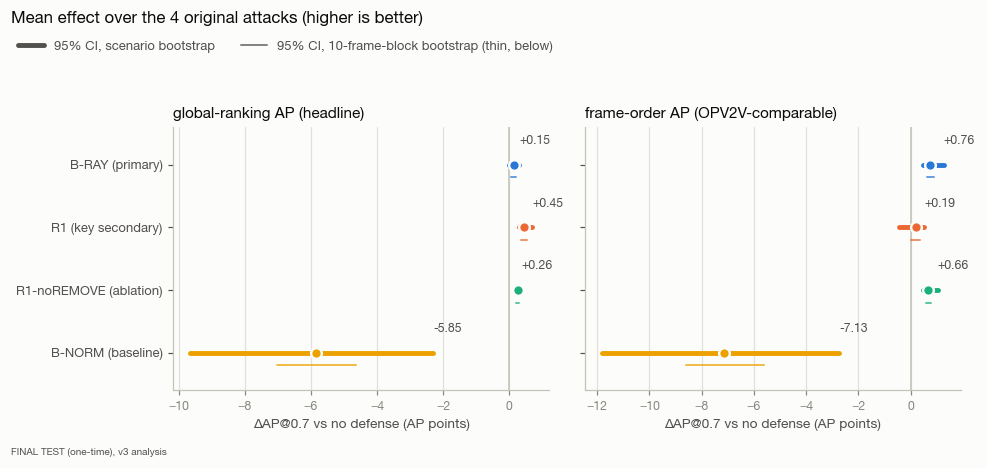

10 plotted values; first rows:
{'ap_definition': 'global', 'method': 'B-RAY', 'point': 0.00147, 'ci95_scenario_lo': -0.0001, 'ci95_scenario_hi': 0.003, 'ci95_block10_lo': 0.0006, 'ci95_block10_hi': 0.0022}
{'ap_definition': 'global', 'method': 'R1', 'point': 0.00454, 'ci95_scenario_lo': 0.0029, 'ci95_scenario_hi': 0.007, 'ci95_block10_lo': 0.0037, 'ci95_block10_hi': 0.0054}
{'ap_definition': 'global', 'method': 'R1_noREMOVE', 'point': 0.00258, 'ci95_scenario_lo': 0.0018, 'ci95_scenario_hi': 0.0036, 'ci95_block10_lo': 0.0021, 'ci95_block10_hi': 0.003}
{'ap_definition': 'global', 'method': 'B-NORM', 'point': -0.05853, 'ci95_scenario_lo': -0.0965, 'ci95_scenario_hi': -0.023, 'ci95_block10_lo': -0.0704, 'ci95_block10_hi': -0.0463}


[None, None, None, None]

In [7]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['01_headline']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 2a. ΔAP@0.7 per condition: clean and original attacks

Every non-PGD condition × defense, both AP definitions, 95% CI from the scenario bootstrap. Ego-only in the table only.

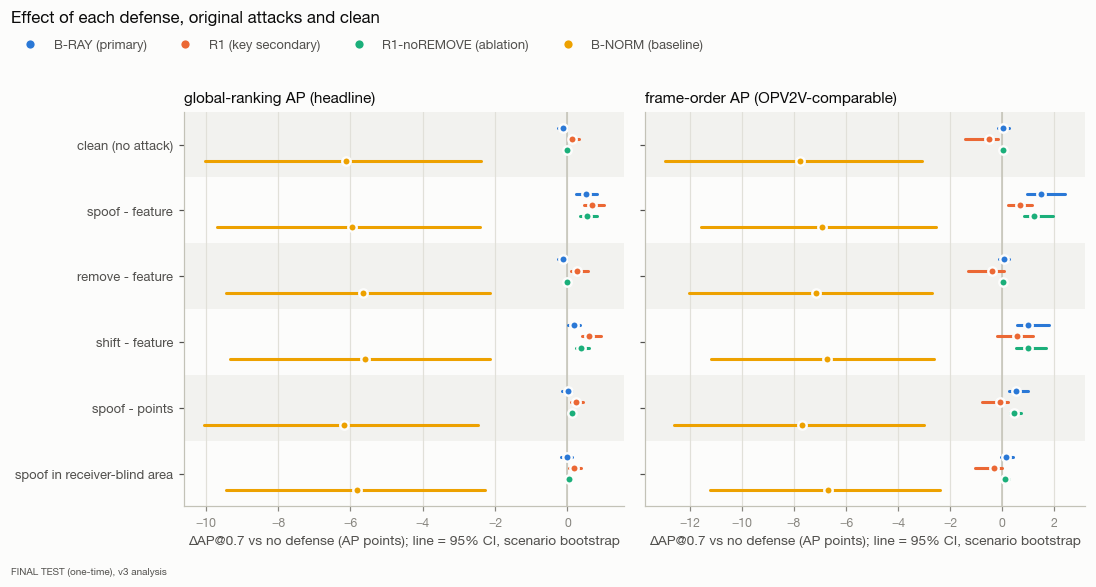

48 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'clean', 'method': 'B-RAY', 'point': -0.00113, 'ci95_scenario_lo': -0.0026, 'ci95_scenario_hi': -0.0001, 'ci95_block10_lo': -0.0019, 'ci95_block10_hi': -0.0005}
{'ap_definition': 'global', 'condition': 'clean', 'method': 'R1', 'point': 0.00138, 'ci95_scenario_lo': 0.0001, 'ci95_scenario_hi': 0.0031, 'ci95_block10_lo': 0.0007, 'ci95_block10_hi': 0.0021}
{'ap_definition': 'global', 'condition': 'clean', 'method': 'R1_noREMOVE', 'point': -9e-05, 'ci95_scenario_lo': -0.0003, 'ci95_scenario_hi': 0.0001, 'ci95_block10_lo': -0.0004, 'ci95_block10_hi': 0.0001}
{'ap_definition': 'global', 'condition': 'clean', 'method': 'B-NORM', 'point': -0.0613, 'ci95_scenario_lo': -0.1003, 'ci95_scenario_hi': -0.024, 'ci95_block10_lo': -0.0737, 'ci95_block10_hi': -0.0482}


[None, None, None, None]

In [8]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['02_per_family']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 2b. ΔAP@0.7 per condition: optimized (PGD) attacks

As 2a for the PGD conditions, on its own scale (PGD effects are much larger than the original attacks').

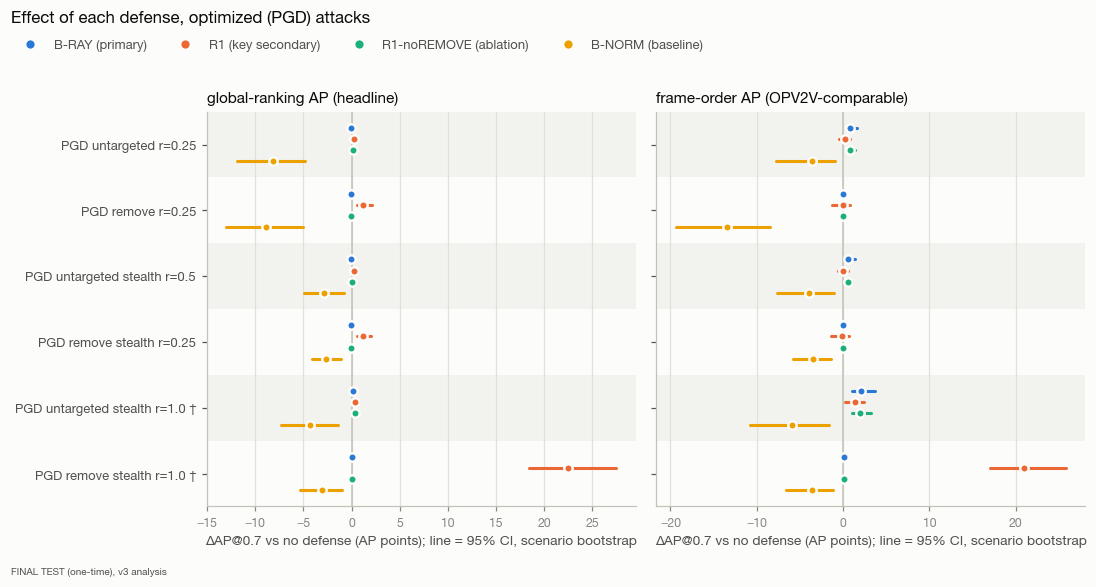

48 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-RAY', 'point': -0.00017, 'ci95_scenario_lo': -0.0014, 'ci95_scenario_hi': 0.0009, 'ci95_block10_lo': -0.0008, 'ci95_block10_hi': 0.0004}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1', 'point': 0.00279, 'ci95_scenario_lo': 0.0008, 'ci95_scenario_hi': 0.0058, 'ci95_block10_lo': 0.0018, 'ci95_block10_hi': 0.0038}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1_noREMOVE', 'point': 0.00132, 'ci95_scenario_lo': 0.0003, 'ci95_scenario_hi': 0.003, 'ci95_block10_lo': 0.0007, 'ci95_block10_hi': 0.002}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-NORM', 'point': -0.08191, 'ci95_scenario_lo': -0.1193, 'ci95_scenario_hi': -0.048, 'ci95_block10_lo': -0.0946, 'ci95_block10_hi': -0.068}


[None, None, None, None]

In [9]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['02b_per_family_pgd']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 3. Clean cost (relative AP@0.7 loss)

Relative AP@0.7 loss on clean frames. The pre-registered success rule requires B-RAY's scenario-CI high ≤ 1% under both AP definitions.

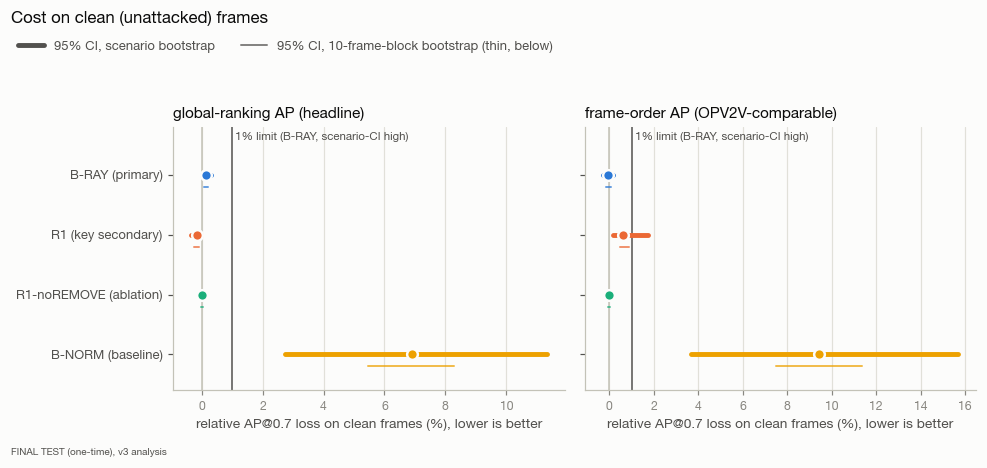

10 plotted values; first rows:
{'ap_definition': 'global', 'method': 'B-RAY', 'point': 0.00127, 'ci95_scenario_lo': 0.0001, 'ci95_scenario_hi': 0.003, 'ci95_block10_lo': 0.0006, 'ci95_block10_hi': 0.0022}
{'ap_definition': 'global', 'method': 'R1', 'point': -0.00156, 'ci95_scenario_lo': -0.0035, 'ci95_scenario_hi': -0.0001, 'ci95_block10_lo': -0.0024, 'ci95_block10_hi': -0.0008}
{'ap_definition': 'global', 'method': 'R1_noREMOVE', 'point': 0.0001, 'ci95_scenario_lo': -0.0001, 'ci95_scenario_hi': 0.0003, 'ci95_block10_lo': -0.0002, 'ci95_block10_hi': 0.0004}
{'ap_definition': 'global', 'method': 'B-NORM', 'point': 0.06916, 'ci95_scenario_lo': 0.0272, 'ci95_scenario_hi': 0.1133, 'ci95_block10_lo': 0.0546, 'ci95_block10_hi': 0.0829}


[None, None, None, None]

In [10]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['03_clean_cost']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 4a. Key secondary: R1 − B-RAY

Paired difference R1 − B-RAY in ΔAP@0.7, the pre-registered means and each non-PGD condition. Each panel quotes the statement the frozen analysis emitted.

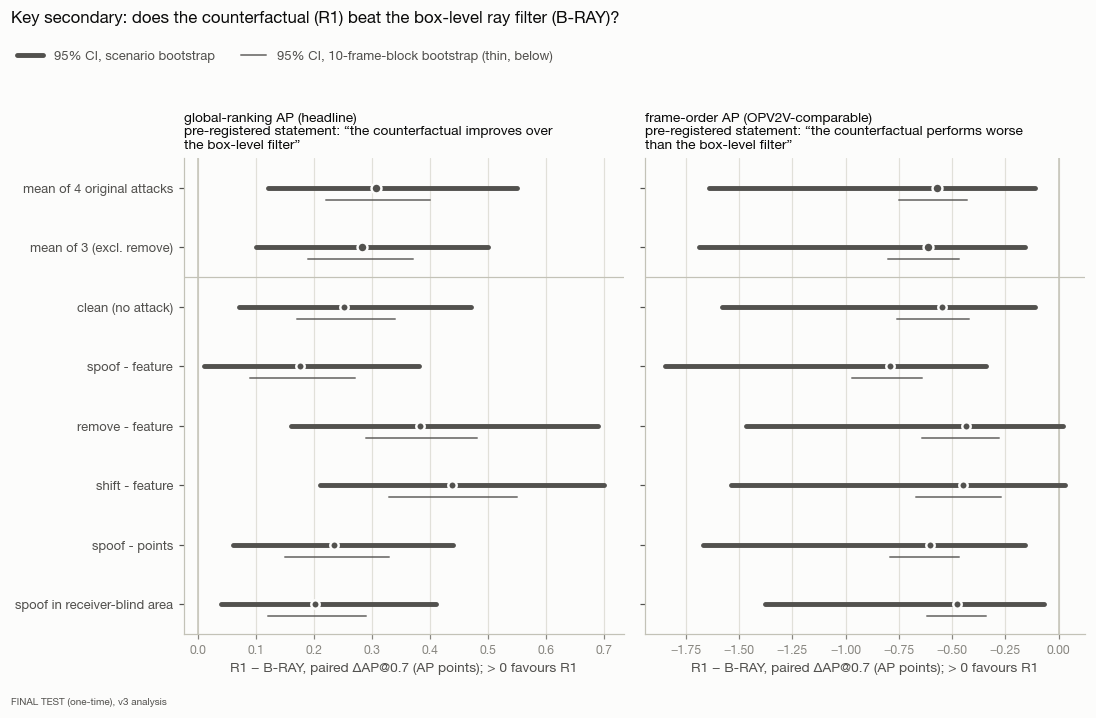

16 plotted values; first rows:
{'ap_definition': 'global', 'statistic': 'paired_mean_orig|R1-B-RAY', 'point': 0.00307, 'ci95_scenario_lo': 0.0012, 'ci95_scenario_hi': 0.0055, 'ci95_block10_lo': 0.0022, 'ci95_block10_hi': 0.004}
{'ap_definition': 'global', 'statistic': 'paired_mean_3|R1-B-RAY', 'point': 0.00282, 'ci95_scenario_lo': 0.001, 'ci95_scenario_hi': 0.005, 'ci95_block10_lo': 0.0019, 'ci95_block10_hi': 0.0037}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|clean', 'point': 0.00251, 'ci95_scenario_lo': 0.0007, 'ci95_scenario_hi': 0.0047, 'ci95_block10_lo': 0.0017, 'ci95_block10_hi': 0.0034}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|spoof_feat', 'point': 0.00176, 'ci95_scenario_lo': 0.0001, 'ci95_scenario_hi': 0.0038, 'ci95_block10_lo': 0.0009, 'ci95_block10_hi': 0.0027}


[None, None, None, None]

In [11]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['04_r1_minus_bray']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 4b. R1 − B-RAY under PGD attacks

Paired difference per PGD condition (descriptive; not part of the key secondary).

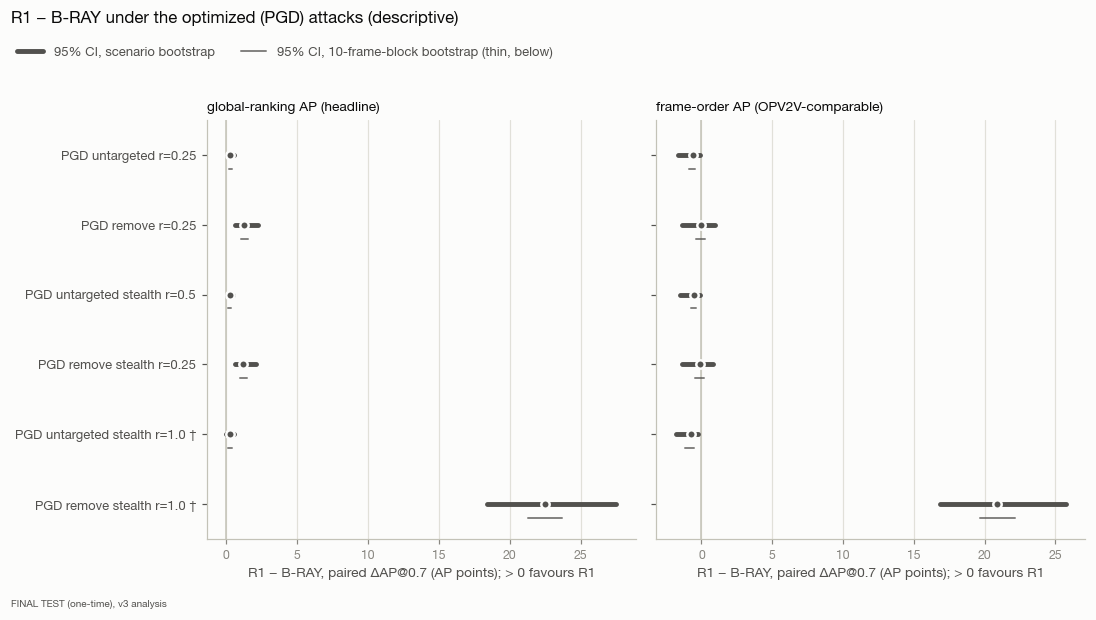

12 plotted values; first rows:
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_untargeted@r0.25', 'point': 0.00296, 'ci95_scenario_lo': 0.0009, 'ci95_scenario_hi': 0.0058, 'ci95_block10_lo': 0.0019, 'ci95_block10_hi': 0.0041}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_remove@r0.25', 'point': 0.01314, 'ci95_scenario_lo': 0.0068, 'ci95_scenario_hi': 0.0224, 'ci95_block10_lo': 0.0107, 'ci95_block10_hi': 0.0157}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_untargeted_stealth@r0.5', 'point': 0.00259, 'ci95_scenario_lo': 0.0007, 'ci95_scenario_hi': 0.0051, 'ci95_block10_lo': 0.0017, 'ci95_block10_hi': 0.0036}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_remove_stealth@r0.25', 'point': 0.01237, 'ci95_scenario_lo': 0.0064, 'ci95_scenario_hi': 0.021, 'ci95_block10_lo': 0.0101, 'ci95_block10_hi': 0.0147}


[None, None, None, None]

In [12]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['04b_r1_minus_bray_pgd']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 5. PGD attacks: recovery

Recovery = ΔAP@0.7 / attack loss per optimized-attack condition. n/a when the attack loss is < 0.005.

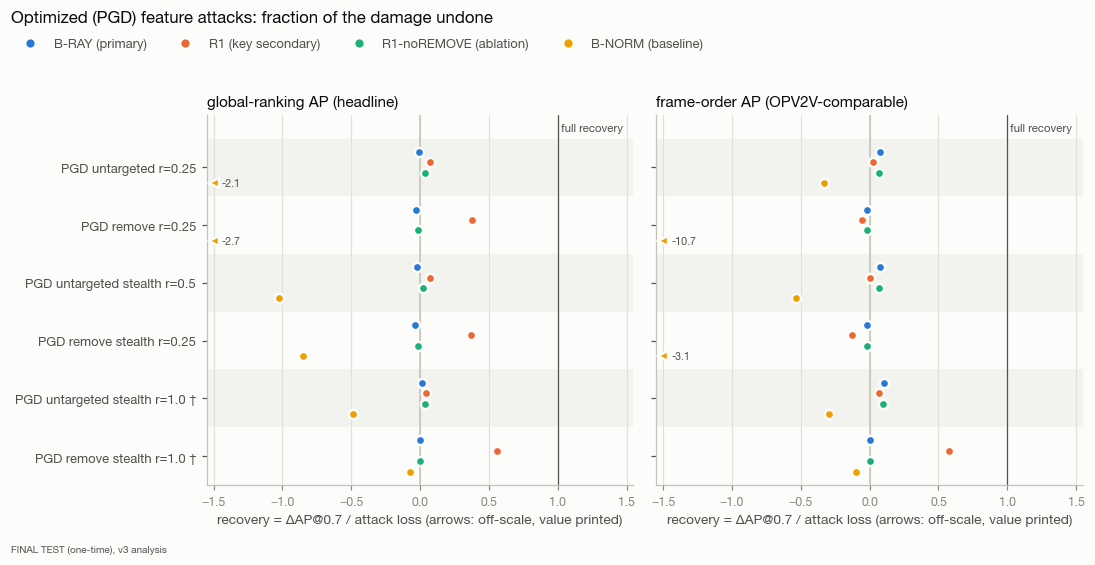

48 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-RAY', 'recovery': -0.00437, 'attack_loss': 0.03949}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1', 'recovery': 0.07062, 'attack_loss': 0.03949}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1_noREMOVE', 'recovery': 0.0334, 'attack_loss': 0.03949}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-NORM', 'recovery': -2.07398, 'attack_loss': 0.03949}


[None, None, None, None]

In [13]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['05_pgd_recovery']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 6. B-NORM catch rate

Share of frames with a sender in which B-NORM flags the attacker; on 'clean' this is the false-flag rate.

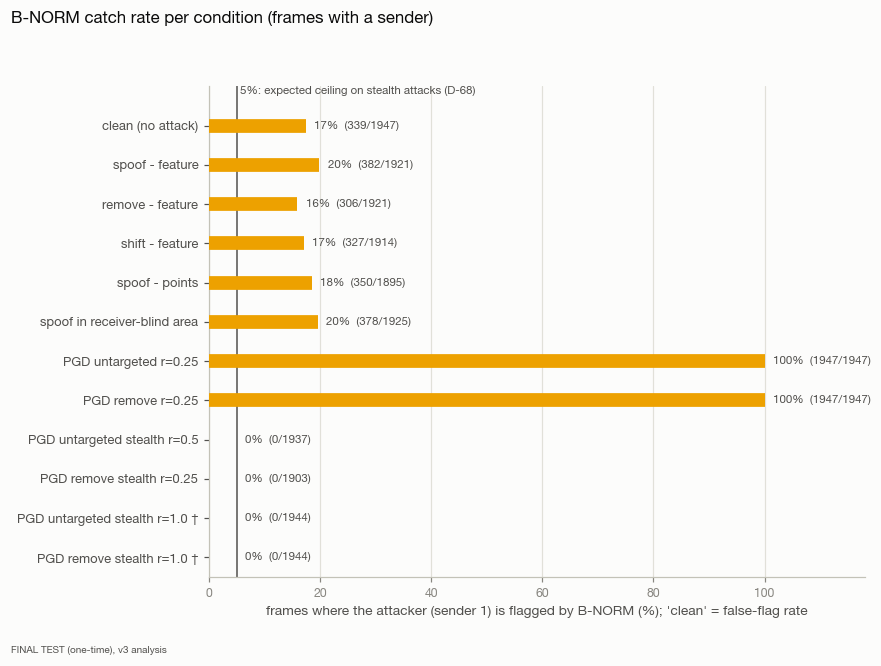

12 plotted values; first rows:
{'condition': 'clean', 'frames_n2': 1947, 'applied': 1947, 'sender1_flagged': 339, 'any_flagged': 493, 'catch_rate': 0.1741}
{'condition': 'spoof_feat', 'frames_n2': 1947, 'applied': 1921, 'sender1_flagged': 382, 'any_flagged': 524, 'catch_rate': 0.1989}
{'condition': 'remove_feat', 'frames_n2': 1947, 'applied': 1921, 'sender1_flagged': 306, 'any_flagged': 474, 'catch_rate': 0.1593}
{'condition': 'shift_feat', 'frames_n2': 1947, 'applied': 1914, 'sender1_flagged': 327, 'any_flagged': 482, 'catch_rate': 0.1708}


[None, None, None, None]

In [14]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['06_bnorm_catch']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 7. Attack strength

Attack loss per condition over all frames (with CI) and over the frames where the attack was realized.

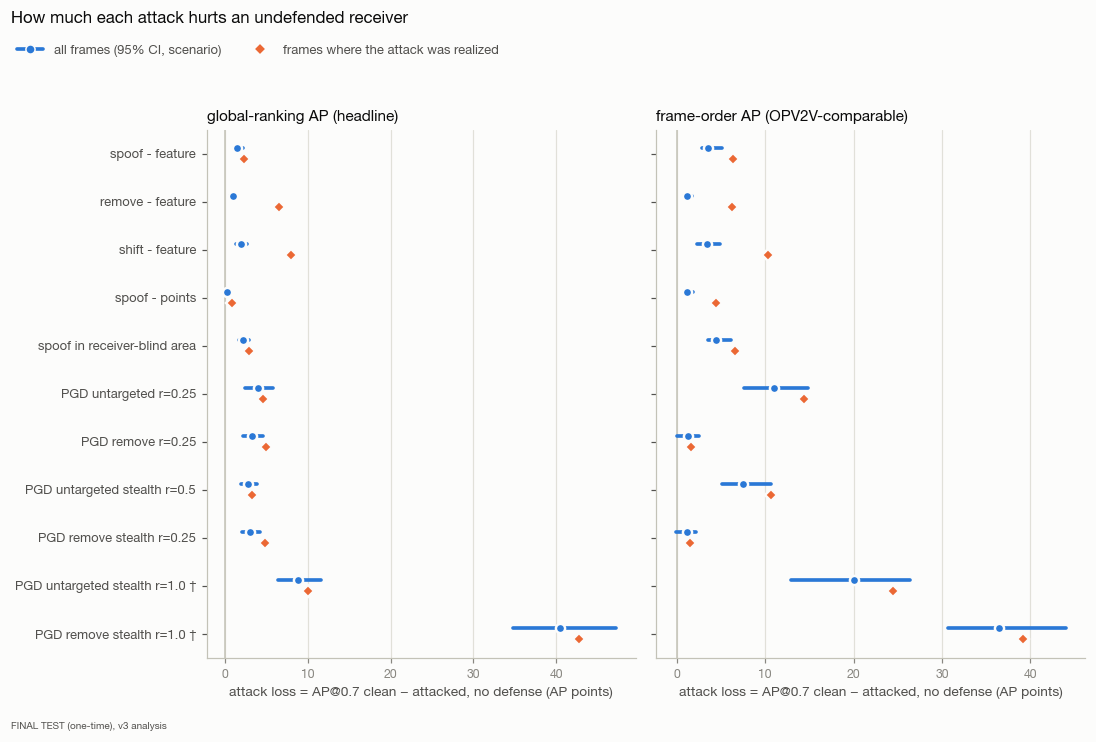

22 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'spoof_feat', 'point': 0.01523, 'ci95_scenario_lo': 0.0108, 'ci95_scenario_hi': 0.0215, 'ci95_block10_lo': 0.0137, 'ci95_block10_hi': 0.0168, 'realized_only_attack_loss': 0.0237, 'realized_frames': 1136}
{'ap_definition': 'global', 'condition': 'remove_feat', 'point': 0.01008, 'ci95_scenario_lo': 0.0066, 'ci95_scenario_hi': 0.0151, 'ci95_block10_lo': 0.0085, 'ci95_block10_hi': 0.0117, 'realized_only_attack_loss': 0.0651, 'realized_frames': 176}
{'ap_definition': 'global', 'condition': 'shift_feat', 'point': 0.01967, 'ci95_scenario_lo': 0.014, 'ci95_scenario_hi': 0.0267, 'ci95_block10_lo': 0.0168, 'ci95_block10_hi': 0.0226, 'realized_only_attack_loss': 0.0803, 'realized_frames': 206}
{'ap_definition': 'global', 'condition': 'spoof_pts', 'point': 0.00271, 'ci95_scenario_lo': 0.0018, 'ci95_scenario_hi': 0.0041, 'ci95_block10_lo': 0.0023, 'ci95_block10_hi': 0.0032, 'realized_only_attack_loss': 0.0083, 'realized_frames'

[None, None, None, None]

In [15]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['07_attack_strength']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 8. B-RAY removals

Boxes B-RAY removed, split by whether they matched a real car.

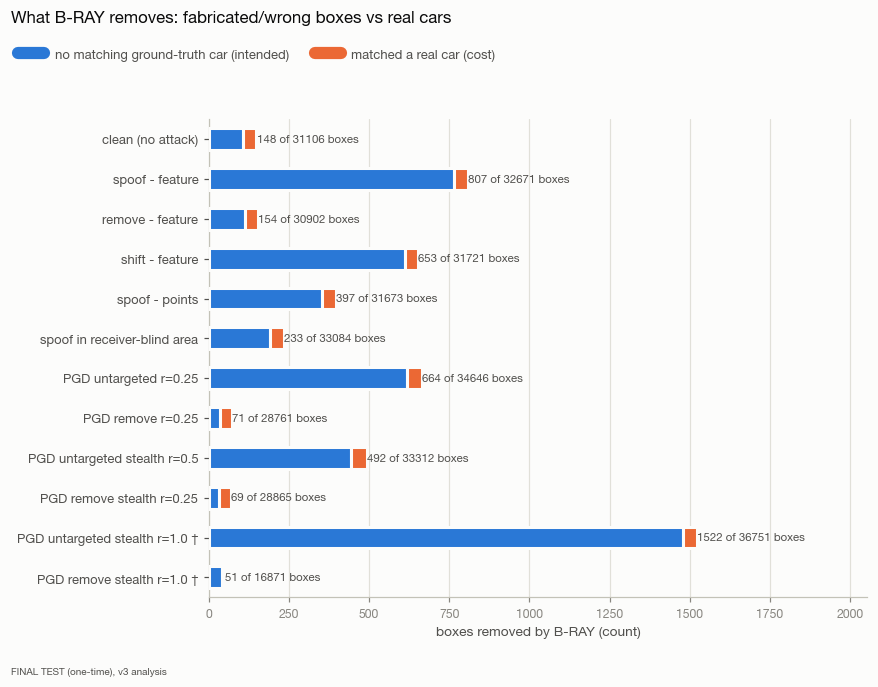

12 plotted values; first rows:
{'condition': 'clean', 'boxes': 31106, 'drop': 148, 'keep': 26034, 'keep_unknown': 3025, 'keep_self': 1899, 'frac_KNOWN': 0.842, 'dropped_gt_matched': 43, 'dropped_unmatched': 105}
{'condition': 'spoof_feat', 'boxes': 32671, 'drop': 807, 'keep': 26120, 'keep_unknown': 3845, 'keep_self': 1899, 'frac_KNOWN': 0.824, 'dropped_gt_matched': 43, 'dropped_unmatched': 764}
{'condition': 'remove_feat', 'boxes': 30902, 'drop': 154, 'keep': 25895, 'keep_unknown': 2969, 'keep_self': 1884, 'frac_KNOWN': 0.843, 'dropped_gt_matched': 43, 'dropped_unmatched': 111}
{'condition': 'shift_feat', 'boxes': 31721, 'drop': 653, 'keep': 26048, 'keep_unknown': 3140, 'keep_self': 1880, 'frac_KNOWN': 0.842, 'dropped_gt_matched': 41, 'dropped_unmatched': 612}


[None, None, None, None]

In [16]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['08_bray_boxes']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 9. R1 gating against ground truth

Contributions (sender × 6.4 m tile) R1 switched off, by their ground-truth label.

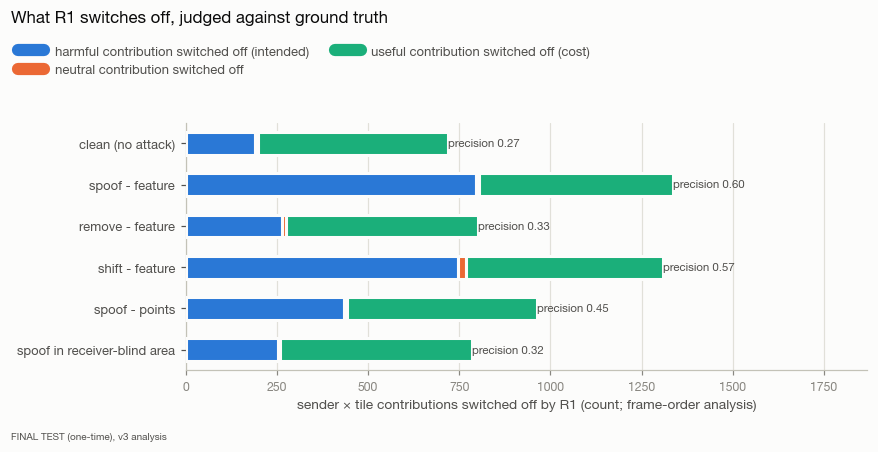

6 plotted values; first rows:
{'condition': 'clean', 'units': 8160, 'n_KNOWN': 4334, 'frac_KNOWN': 0.531, 'gated': 718, 'gated_harmful': 190, 'gated_neutral': 7, 'false_rejections_useful': 521, 'precision': 0.265, 'harmful_units': 1426, 'harmful_KNOWN': 792, 'useful_units': 4595}
{'condition': 'spoof_feat', 'units': 9907, 'n_KNOWN': 5218, 'frac_KNOWN': 0.527, 'gated': 1335, 'gated_harmful': 795, 'gated_neutral': 8, 'false_rejections_useful': 532, 'precision': 0.596, 'harmful_units': 2875, 'harmful_KNOWN': 1475, 'useful_units': 4863}
{'condition': 'remove_feat', 'units': 8252, 'n_KNOWN': 4412, 'frac_KNOWN': 0.535, 'gated': 800, 'gated_harmful': 264, 'gated_neutral': 10, 'false_rejections_useful': 526, 'precision': 0.33, 'harmful_units': 1544, 'harmful_KNOWN': 887, 'useful_units': 4629}
{'condition': 'shift_feat', 'units': 9526, 'n_KNOWN': 5437, 'frac_KNOWN': 0.571, 'gated': 1309, 'gated_harmful': 747, 'gated_neutral': 20, 'false_rejections_useful': 542, 'precision': 0.571, 'harmful_unit

[None, None, None, None]

In [17]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['09_r1_units']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 10. Effect by number of cars

Mean ΔAP@0.7 over the 4 original attacks per agent count (frozen v2 analysis, frame-order AP).

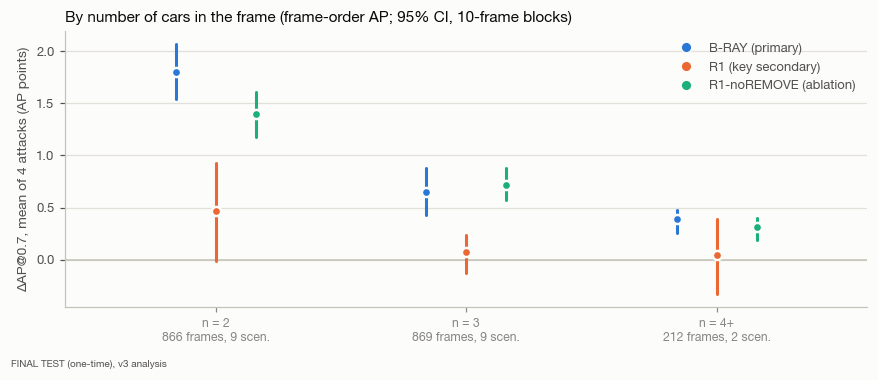

9 plotted values; first rows:
{'n_agents': '2', 'frames': 866, 'scenarios': 9, 'method': 'B-RAY', 'point': 0.01801, 'ci95_block10_lo': 0.0154, 'ci95_block10_hi': 0.0207}
{'n_agents': '2', 'frames': 866, 'scenarios': 9, 'method': 'R1', 'point': 0.0047, 'ci95_block10_lo': -0.0001, 'ci95_block10_hi': 0.0093}
{'n_agents': '2', 'frames': 866, 'scenarios': 9, 'method': 'R1_noREMOVE', 'point': 0.01394, 'ci95_block10_lo': 0.0118, 'ci95_block10_hi': 0.0161}
{'n_agents': '3', 'frames': 869, 'scenarios': 9, 'method': 'B-RAY', 'point': 0.0065, 'ci95_block10_lo': 0.0043, 'ci95_block10_hi': 0.0088}


[None, None, None, None]

In [18]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['10_by_agents']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

## Per-condition tables

In [19]:
for d in DEFS:
    display(Markdown(f'**{DEF_NAME[d]}**'))
    display(Markdown(T.per_family(inp, d)))

**global-ranking AP (headline)**

| Condition | B-RAY (primary) | R1 (key secondary) | R1-noREMOVE (ablation) | B-NORM (baseline) | Ego-only |
|---|---|---|---|---|---|
| clean (no attack) | -0.11 [-0.26, -0.01] | +0.14 [+0.01, +0.31] | -0.01 [-0.03, +0.01] | -6.13 [-10.03, -2.40] | -21.21 [-24.26, -17.27] |
| spoof - feature | +0.51 [+0.25, +0.83] | +0.68 [+0.45, +1.02] | +0.55 [+0.35, +0.82] | -5.95 [-9.70, -2.41] | -19.69 [-22.75, -15.79] |
| remove - feature | -0.11 [-0.27, -0.00] | +0.27 [+0.10, +0.56] | -0.01 [-0.05, +0.02] | -5.67 [-9.45, -2.13] | -20.21 [-23.28, -16.15] |
| shift - feature | +0.17 [+0.03, +0.36] | +0.61 [+0.39, +0.93] | +0.38 [+0.24, +0.59] | -5.61 [-9.33, -2.13] | -19.25 [-22.51, -15.05] |
| spoof - points | +0.02 [-0.14, +0.13] | +0.25 [+0.10, +0.44] | +0.11 [+0.06, +0.18] | -6.18 [-10.06, -2.47] | -20.94 [-23.95, -17.08] |
| spoof in receiver-blind area | -0.01 [-0.18, +0.14] | +0.19 [+0.05, +0.37] | +0.05 [+0.00, +0.11] | -5.81 [-9.43, -2.29] | -19.00 [-22.11, -15.15] |
| PGD untargeted r=0.25 | -0.02 [-0.14, +0.09] | +0.28 [+0.08, +0.58] | +0.13 [+0.03, +0.30] | -8.19 [-11.93, -4.80] | -17.27 [-20.15, -13.53] |
| PGD remove r=0.25 | -0.10 [-0.23, -0.01] | +1.22 [+0.61, +2.15] | -0.04 [-0.08, -0.01] | -8.89 [-13.01, -5.08] | -17.97 [-20.77, -14.14] |
| PGD untargeted stealth r=0.5 | -0.06 [-0.21, +0.05] | +0.20 [+0.03, +0.46] | +0.06 [-0.03, +0.17] | -2.83 [-4.94, -0.80] | -18.45 [-21.49, -14.47] |
| PGD remove stealth r=0.25 | -0.10 [-0.24, -0.01] | +1.13 [+0.55, +1.99] | -0.04 [-0.09, -0.01] | -2.61 [-4.14, -1.06] | -18.15 [-20.98, -14.29] |
| PGD untargeted stealth r=1.0 † | +0.12 [-0.02, +0.30] | +0.40 [+0.14, +0.80] | +0.33 [+0.12, +0.66] | -4.32 [-7.28, -1.37] | -12.36 [-16.32, -7.39] |
| PGD remove stealth r=1.0 † | -0.01 [-0.05, +0.02] | +22.50 [+18.41, +27.48] | +0.07 [+0.01, +0.14] | -3.06 [-5.36, -1.03] | +19.19 [+14.29, +25.04] |

**frame-order AP (OPV2V-comparable)**

| Condition | B-RAY (primary) | R1 (key secondary) | R1-noREMOVE (ablation) | B-NORM (baseline) | Ego-only |
|---|---|---|---|---|---|
| clean (no attack) | +0.04 [-0.15, +0.24] | -0.51 [-1.44, -0.15] | +0.03 [+0.01, +0.08] | -7.76 [-12.97, -3.07] | -26.52 [-31.42, -21.36] |
| spoof - feature | +1.47 [+0.96, +2.41] | +0.68 [+0.21, +1.12] | +1.20 [+0.83, +1.94] | -6.93 [-11.57, -2.54] | -22.95 [-28.09, -17.45] |
| remove - feature | +0.05 [-0.12, +0.24] | -0.38 [-1.31, +0.05] | +0.04 [+0.00, +0.11] | -7.16 [-12.02, -2.69] | -25.36 [-30.51, -19.82] |
| shift - feature | +1.00 [+0.55, +1.78] | +0.55 [-0.22, +1.16] | +0.99 [+0.53, +1.67] | -6.73 [-11.19, -2.64] | -23.11 [-28.87, -17.25] |
| spoof - points | +0.51 [+0.26, +0.98] | -0.09 [-0.77, +0.20] | +0.43 [+0.31, +0.73] | -7.69 [-12.62, -3.00] | -25.40 [-30.41, -20.13] |
| spoof in receiver-blind area | +0.14 [-0.05, +0.41] | -0.34 [-1.04, -0.02] | +0.11 [+0.05, +0.24] | -6.70 [-11.23, -2.38] | -22.13 [-27.04, -16.81] |
| PGD untargeted r=0.25 | +0.83 [+0.40, +1.57] | +0.24 [-0.51, +0.77] | +0.76 [+0.44, +1.38] | -3.64 [-7.72, -0.92] | -15.50 [-22.71, -8.70] |
| PGD remove r=0.25 | -0.02 [-0.19, +0.10] | -0.07 [-1.34, +0.84] | -0.03 [-0.06, +0.01] | -13.40 [-19.41, -8.43] | -25.26 [-30.23, -20.36] |
| PGD untargeted stealth r=0.5 | +0.58 [+0.16, +1.34] | +0.03 [-0.65, +0.53] | +0.53 [+0.24, +1.07] | -4.00 [-7.69, -1.01] | -19.00 [-25.85, -11.66] |
| PGD remove stealth r=0.25 | -0.02 [-0.20, +0.12] | -0.14 [-1.40, +0.73] | -0.02 [-0.06, +0.01] | -3.51 [-5.76, -1.40] | -25.38 [-30.51, -20.36] |
| PGD untargeted stealth r=1.0 † | +2.09 [+1.00, +3.70] | +1.33 [+0.19, +2.44] | +1.93 [+1.01, +3.27] | -5.87 [-10.77, -1.58] | -6.42 [-17.85, +3.34] |
| PGD remove stealth r=1.0 † | +0.06 [-0.01, +0.14] | +20.94 [+16.96, +25.78] | +0.10 [+0.04, +0.19] | -3.62 [-6.63, -1.13] | +9.99 [+3.88, +16.79] |

## PGD, B-NORM and descriptive expected-outcome checks

In [20]:
if inp.pgd_conditions:
    display(Markdown(T.pgd(inp)))
    e = T.expected_outcome_checks(inp)
    display(Markdown(e or 'no operational checks in the preregistration'))
    n = T.d70_note(inp)
    display(Markdown(n)) if n else None

| Condition | attack loss global | attack loss frame | recovery B-RAY (primary) (global / frame) | recovery R1 (key secondary) (global / frame) | recovery R1-noREMOVE (ablation) (global / frame) | recovery B-NORM (baseline) (global / frame) | recovery Ego-only (global / frame) | B-NORM catch | stealth-infeasible / frames with sender | realized / applied |
|---|---|---|---|---|---|---|---|---|---|---|
| PGD untargeted r=0.25 | +3.95 | +11.02 | -0.00 / 0.08 | 0.07 / 0.02 | 0.03 / 0.07 | -2.07 / -0.33 | -4.37 / -1.41 | 100% | 0/1947 | 1541/1947 |
| PGD remove r=0.25 | +3.25 | +1.26 | -0.03 / -0.02 | 0.37 / -0.05 | -0.01 / -0.02 | -2.74 / -10.66 | -5.53 / -20.10 | 100% | 0/1947 | 1233/1947 |
| PGD untargeted stealth r=0.5 | +2.77 | +7.52 | -0.02 / 0.08 | 0.07 / 0.00 | 0.02 / 0.07 | -1.02 / -0.53 | -6.67 / -2.53 | 0% | 10/1947 | 1402/1937 |
| PGD remove stealth r=0.25 | +3.06 | +1.14 | -0.03 / -0.02 | 0.37 / -0.13 | -0.01 / -0.02 | -0.85 / -3.09 | -5.92 / -22.36 | 0% | 44/1947 | 1193/1903 |
| PGD untargeted stealth r=1.0 † | +8.86 | +20.10 | 0.01 / 0.10 | 0.04 / 0.07 | 0.04 / 0.10 | -0.49 / -0.29 | -1.39 / -0.32 | 0% | 3/1947 | 1709/1944 |
| PGD remove stealth r=1.0 † | +40.41 | +36.51 | -0.00 / 0.00 | 0.56 / 0.57 | 0.00 / 0.00 | -0.08 / -0.10 | 0.47 / 0.27 | 0% | 3/1947 | 1944/1944 |

| Condition | B-RAY ≈ 0 (point recovery < 0.10 under both AP definitions) | R1 > 0 (R1 dAP@0.7 scenario-CI low > 0 under both AP definitions) | B-NORM ≤ 5% (sender-1 flag rate over attacked frames <= 0.05) |
|---|---|---|---|
| PGD untargeted r=0.25 | yes | not applicable | not applicable |
| PGD remove r=0.25 | yes | no | not applicable |
| PGD untargeted stealth r=0.5 | yes | not applicable | yes |
| PGD remove stealth r=0.25 | yes | no | yes |
| PGD untargeted stealth r=1.0 † | no | not applicable | yes |
| PGD remove stealth r=1.0 † | yes | yes | yes |

† pgd_remove_stealth@r1.0, pgd_untargeted_stealth@r1.0: strong-attack level, added after seeing block-H development results (D-70, secondary; never used for a criterion).

## Realized-only effects

In [21]:
for d in DEFS:
    display(Markdown(f'**{DEF_NAME[d]}**'))
    display(Markdown(T.realized_only(inp, d)))

**global-ranking AP (headline)**

| Condition | realized frames | attack loss | B-RAY (primary) ΔAP (recovery) | R1 (key secondary) ΔAP (recovery) | R1-noREMOVE (ablation) ΔAP (recovery) | B-NORM (baseline) ΔAP (recovery) | Ego-only ΔAP (recovery) |
|---|---|---|---|---|---|---|---|
| spoof - feature | 1136 | +2.37 | +0.82 (0.35) | +0.90 (0.38) | +0.83 (0.35) | -7.47 (-3.15) | -20.47 (-8.64) |
| remove - feature | 176 | +6.51 | -0.22 (-0.03) | +1.79 (0.28) | -0.03 (-0.01) | -9.05 (-1.39) | -20.60 (-3.16) |
| shift - feature | 206 | +8.03 | +0.30 (0.04) | +2.04 (0.25) | +1.10 (0.14) | -8.27 (-1.03) | -17.20 (-2.14) |
| spoof - points | 563 | +0.83 | +0.30 (0.36) | +0.42 (0.51) | +0.35 (0.42) | -7.85 (-9.48) | -21.99 (-26.57) |
| spoof in receiver-blind area | 1412 | +2.94 | +0.00 (0.00) | +0.13 (0.04) | +0.07 (0.02) | -6.51 (-2.21) | -19.69 (-6.69) |
| PGD untargeted r=0.25 | 1541 | +4.61 | -0.01 (-0.00) | +0.34 (0.07) | +0.15 (0.03) | -8.89 (-1.93) | -18.29 (-3.97) |
| PGD remove r=0.25 | 1233 | +5.00 | -0.13 (-0.03) | +1.87 (0.37) | -0.05 (-0.01) | -8.47 (-1.70) | -18.32 (-3.67) |
| PGD untargeted stealth r=0.5 | 1402 | +3.32 | -0.05 (-0.02) | +0.27 (0.08) | +0.07 (0.02) | -3.14 (-0.95) | -19.37 (-5.84) |
| PGD remove stealth r=0.25 | 1193 | +4.86 | -0.14 (-0.03) | +1.79 (0.37) | -0.06 (-0.01) | -2.22 (-0.46) | -18.25 (-3.75) |
| PGD untargeted stealth r=1.0 † | 1709 | +10.10 | +0.16 (0.02) | +0.45 (0.04) | +0.38 (0.04) | -4.69 (-0.47) | -12.53 (-1.24) |
| PGD remove stealth r=1.0 † | 1944 | +42.71 | -0.02 (-0.00) | +23.73 (0.56) | +0.07 (0.00) | -3.19 (-0.07) | +20.12 (0.47) |

**frame-order AP (OPV2V-comparable)**

| Condition | realized frames | attack loss | B-RAY (primary) ΔAP (recovery) | R1 (key secondary) ΔAP (recovery) | R1-noREMOVE (ablation) ΔAP (recovery) | B-NORM (baseline) ΔAP (recovery) | Ego-only ΔAP (recovery) |
|---|---|---|---|---|---|---|---|
| spoof - feature | 1136 | +6.32 | +2.46 (0.39) | +1.45 (0.23) | +2.05 (0.32) | -8.48 (-1.34) | -23.00 (-3.64) |
| remove - feature | 176 | +6.24 | -0.16 (-0.03) | +0.89 (0.14) | -0.03 (-0.01) | -11.94 (-1.92) | -24.04 (-3.85) |
| shift - feature | 206 | +10.34 | +1.24 (0.12) | +2.05 (0.20) | +1.80 (0.17) | -10.35 (-1.00) | -19.56 (-1.89) |
| spoof - points | 563 | +4.38 | +1.74 (0.40) | +0.93 (0.21) | +1.51 (0.34) | -9.45 (-2.15) | -25.09 (-5.72) |
| spoof in receiver-blind area | 1412 | +6.58 | +0.15 (0.02) | -0.41 (-0.06) | +0.15 (0.02) | -7.23 (-1.10) | -22.91 (-3.48) |
| PGD untargeted r=0.25 | 1541 | +14.43 | +1.03 (0.07) | +0.46 (0.03) | +1.00 (0.07) | -2.63 (-0.18) | -15.17 (-1.05) |
| PGD remove r=0.25 | 1233 | +1.63 | -0.12 (-0.07) | +0.23 (0.14) | -0.04 (-0.03) | -14.12 (-8.64) | -26.79 (-16.40) |
| PGD untargeted stealth r=0.5 | 1402 | +10.64 | +0.87 (0.08) | +0.29 (0.03) | +0.83 (0.08) | -4.25 (-0.40) | -18.37 (-1.73) |
| PGD remove stealth r=0.25 | 1193 | +1.54 | -0.12 (-0.08) | +0.06 (0.04) | -0.05 (-0.03) | -3.01 (-1.95) | -26.62 (-17.30) |
| PGD untargeted stealth r=1.0 † | 1709 | +24.49 | +2.54 (0.10) | +1.69 (0.07) | +2.35 (0.10) | -6.20 (-0.25) | -4.61 (-0.19) |
| PGD remove stealth r=1.0 † | 1944 | +39.22 | +0.01 (0.00) | +22.38 (0.57) | +0.11 (0.00) | -3.91 (-0.10) | +10.16 (0.26) |

## Interpretation (AUTHOR)

*To be written after reading the cells above. Keep to what the numbers support; quote the pre-registered statements as emitted.*

## Run provenance

In [22]:
import matplotlib, numpy, jinja2
print('python', platform.python_version(), '| numpy', numpy.__version__, '| matplotlib', matplotlib.__version__,
      '| jinja2', jinja2.__version__)
print('platform', platform.platform())
print('wall time %.1f s' % (time.time() - T0))

python 3.10.20 | numpy 1.26.4 | matplotlib 3.8.4 | jinja2 3.1.6
platform macOS-27.0-arm64-arm-64bit
wall time 1.7 s
